# Notebook 8 — Financial Intelligence KPIs

## Objective

This notebook converts complaint data, sentiment predictions, discovered topics and company-response outcomes into interpretable financial-intelligence indicators.

The analysis will identify:

- companies and products generating the largest complaint volumes;
- companies with concentrated negative narrative sentiment;
- high-volume and high-negativity complaint themes;
- untimely-response patterns;
- monetary and non-monetary relief outcomes;
- company–product combinations requiring closer operational attention;
- transparent composite complaint-risk indicators.

## Data Strategy

Two datasets are used for different purposes:

1. **Complete complaint dataset**

   Contains all 566,694 complaints and is used for real complaint volume, company response, timeliness and relief metrics.

2. **Narrative intelligence dataset**

   Contains 272,466 complaints with narratives, topic assignments and FinBERT predictions. It is used for sentiment and topic-based indicators.

The narrative dataset will be merged onto the complete complaint dataset using `complaint_id`. Complaints without narratives will remain in the analysis, but their sentiment and topic fields will be missing.

## Methodology

The notebook will:

1. Validate and combine the operational and narrative-intelligence datasets.
2. Calculate company, product and company–product metrics.
3. Apply minimum-volume thresholds to avoid unstable comparisons.
4. Normalise selected indicators onto comparable scales.
5. Construct transparent composite complaint-risk indicators.
6. inspect the highest-scoring companies and products.
7. Export KPI tables for the SQL analytics layer and dashboards.

## Interpretation Limitation

The resulting indicators measure complaint-related operational and consumer-experience signals. They do not measure a company’s financial solvency, profitability, creditworthiness or regulatory guilt.

Sentiment and topic components remain exploratory because they are based on pretrained and unsupervised models without human-labelled complaint reference data.

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/Users/ishika/Documents/AIProject"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

FULL_COMPLAINTS_PATH = (
    PROCESSED_DIR /
    "cleaned_full_with_taxonomy.csv"
)

NARRATIVE_INTELLIGENCE_PATH = (
    PROJECT_DIR /
    "outputs" /
    "notebook7_analysis" /
    "full_narratives_with_topics_and_sentiment.csv.gz"
)

input_files = pd.DataFrame({
    "dataset": [
        "Complete complaint dataset",
        "Narrative intelligence dataset"
    ],
    "path": [
        str(FULL_COMPLAINTS_PATH),
        str(NARRATIVE_INTELLIGENCE_PATH)
    ],
    "exists": [
        FULL_COMPLAINTS_PATH.exists(),
        NARRATIVE_INTELLIGENCE_PATH.exists()
    ]
})

display(input_files)

if not input_files["exists"].all():
    raise FileNotFoundError(
        "One or more required input files could not be found."
    )

,dataset,path,exists
0,Complete complaint dataset,/Users/ishika/Documents/AIProject/data/process...,True
1,Narrative intelligence dataset,/Users/ishika/Documents/AIProject/outputs/note...,True


## 3. Load Operational and Narrative-Intelligence Data

Only columns required for KPI construction are loaded from the complete complaint dataset. This reduces memory usage while retaining company, product, issue, response, timeliness and narrative-availability information.

Topic and sentiment fields are loaded separately from the Notebook 7 output.

In [8]:
operational_columns = [
    "complaint_id",
    "date_received",
    "product",
    "issue",
    "sub_issue",
    "company",
    "state",
    "company_response_to_consumer",
    "timely_response",
    "has_narrative"
]

full_header = pd.read_csv(
    FULL_COMPLAINTS_PATH,
    nrows=0
).columns.tolist()

missing_operational_columns = [
    column
    for column in operational_columns
    if column not in full_header
]

if missing_operational_columns:
    raise ValueError(
        "Missing operational columns: "
        + str(missing_operational_columns)
    )

full_complaints = pd.read_csv(
    FULL_COMPLAINTS_PATH,
    usecols=operational_columns,
    low_memory=False
)

narrative_columns = [
    "complaint_id",
    "topic_text_id",
    "topic_id",
    "topic_key",
    "topic_label",
    "topic_type",
    "topic_assignment_strength",
    "topic_assignment_corrected",
    "sentiment_label",
    "negative_probability",
    "neutral_probability",
    "positive_probability",
    "sentiment_confidence"
]

narrative_intelligence = pd.read_csv(
    NARRATIVE_INTELLIGENCE_PATH,
    compression="gzip",
    usecols=narrative_columns,
    low_memory=False
)

full_complaints["complaint_id"] = (
    full_complaints["complaint_id"].astype(str)
)

narrative_intelligence["complaint_id"] = (
    narrative_intelligence["complaint_id"].astype(str)
)

loading_validation = pd.DataFrame({
    "check": [
        "Complete complaint rows",
        "Narrative intelligence rows",
        "Duplicate IDs in complete data",
        "Duplicate IDs in narrative data",
        "Products in complete data",
        "Products with narrative intelligence"
    ],
    "value": [
        len(full_complaints),
        len(narrative_intelligence),
        full_complaints[
            "complaint_id"
        ].duplicated().sum(),
        narrative_intelligence[
            "complaint_id"
        ].duplicated().sum(),
        full_complaints["product"].nunique(),
        full_complaints.loc[
            full_complaints["complaint_id"].isin(
                narrative_intelligence["complaint_id"]
            ),
            "product"
        ].nunique()
    ]
})

display(loading_validation)

print(
    "\nOperational dataset shape:",
    full_complaints.shape
)

print(
    "Narrative intelligence shape:",
    narrative_intelligence.shape
)

,check,value
0,Complete complaint rows,566694
1,Narrative intelligence rows,272466
2,Duplicate IDs in complete data,0
3,Duplicate IDs in narrative data,0
4,Products in complete data,5
5,Products with narrative intelligence,5



Operational dataset shape: (566694, 10)
Narrative intelligence shape: (272466, 13)


## 4. Create the Unified KPI Dataset

Narrative intelligence is merged onto the complete complaint dataset using a left join. This preserves every complaint, including those without consumer narratives.

Operational indicators use all complaints. Sentiment and topic indicators use only complaints with narrative intelligence, and their denominators will be reported explicitly.

In [9]:
kpi_data = full_complaints.merge(
    narrative_intelligence,
    on="complaint_id",
    how="left",
    validate="one_to_one"
)

# Parse complaint dates
kpi_data["date_received"] = pd.to_datetime(
    kpi_data["date_received"],
    errors="coerce"
)

kpi_data["complaint_month"] = (
    kpi_data["date_received"]
    .dt.to_period("M")
    .astype("string")
)

# Narrative coverage
kpi_data["has_narrative_intelligence"] = (
    kpi_data["sentiment_label"].notna()
)

# Operational-response indicators
kpi_data["is_untimely"] = (
    kpi_data["timely_response"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("no")
)

kpi_data["has_monetary_relief"] = (
    kpi_data["company_response_to_consumer"]
    .eq("Closed with monetary relief")
)

kpi_data["has_non_monetary_relief"] = (
    kpi_data["company_response_to_consumer"]
    .eq("Closed with non-monetary relief")
)

kpi_data["has_any_relief"] = (
    kpi_data["has_monetary_relief"]
    | kpi_data["has_non_monetary_relief"]
)

# Narrative indicators remain missing when no narrative exists
kpi_data["is_negative_sentiment"] = np.where(
    kpi_data["has_narrative_intelligence"],
    kpi_data["sentiment_label"].eq("negative"),
    np.nan
)

kpi_data["is_template_heavy_topic"] = np.where(
    kpi_data["has_narrative_intelligence"],
    kpi_data["topic_type"].eq(
        "Template-heavy theme"
    ),
    np.nan
)

kpi_data["is_topic_outlier"] = np.where(
    kpi_data["has_narrative_intelligence"],
    kpi_data["topic_type"].eq("Outlier"),
    np.nan
)

kpi_data["is_topic_eligible"] = np.where(
    kpi_data["has_narrative_intelligence"],
    kpi_data["topic_type"].ne("Not eligible"),
    np.nan
)

merge_validation = pd.DataFrame({
    "check": [
        "Unified KPI rows",
        "Expected complete rows",
        "Duplicate complaint IDs",
        "Rows with narrative intelligence",
        "Rows without narrative intelligence",
        "Missing sentiment among narrative rows",
        "Missing topic label among narrative rows",
        "Unparsed complaint dates"
    ],
    "value": [
        len(kpi_data),
        len(full_complaints),
        kpi_data["complaint_id"].duplicated().sum(),
        kpi_data[
            "has_narrative_intelligence"
        ].sum(),
        (
            ~kpi_data[
                "has_narrative_intelligence"
            ]
        ).sum(),
        kpi_data.loc[
            kpi_data[
                "has_narrative_intelligence"
            ],
            "sentiment_label"
        ].isna().sum(),
        kpi_data.loc[
            kpi_data[
                "has_narrative_intelligence"
            ],
            "topic_label"
        ].isna().sum(),
        kpi_data["date_received"].isna().sum()
    ]
})

display(merge_validation)

/var/folders/kf/zl0ktfsd2d577bprgzdycbzr0000gn/T/ipykernel_19524/2982952422.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  kpi_data["date_received"]


,check,value
0,Unified KPI rows,566694
1,Expected complete rows,566694
2,Duplicate complaint IDs,0
3,Rows with narrative intelligence,272466
4,Rows without narrative intelligence,294228
5,Missing sentiment among narrative rows,0
6,Missing topic label among narrative rows,0
7,Unparsed complaint dates,0


## 5. Product-Level KPI Baseline

Product-level indicators provide the first financial-intelligence overview.

Operational rates use all complaints as their denominator. Sentiment and topic rates use only complaints containing narrative intelligence. Narrative coverage is reported so that products with different levels of narrative availability can be interpreted fairly.

Relief rates describe company response outcomes and are not automatically treated as positive or negative performance.

In [10]:
product_kpis = (
    kpi_data
    .groupby("product")
    .agg(
        total_complaints=(
            "complaint_id",
            "size"
        ),
        narrative_complaints=(
            "has_narrative_intelligence",
            "sum"
        ),
        negative_narrative_complaints=(
            "is_negative_sentiment",
            "sum"
        ),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        untimely_complaints=(
            "is_untimely",
            "sum"
        ),
        monetary_relief_complaints=(
            "has_monetary_relief",
            "sum"
        ),
        non_monetary_relief_complaints=(
            "has_non_monetary_relief",
            "sum"
        ),
        any_relief_complaints=(
            "has_any_relief",
            "sum"
        ),
        template_heavy_complaints=(
            "is_template_heavy_topic",
            "sum"
        ),
        topic_outlier_complaints=(
            "is_topic_outlier",
            "sum"
        ),
        unique_companies=(
            "company",
            "nunique"
        ),
        unique_issues=(
            "issue",
            "nunique"
        )
    )
    .reset_index()
)

product_kpis["narrative_coverage_percentage"] = (
    product_kpis["narrative_complaints"]
    / product_kpis["total_complaints"]
    * 100
)

product_kpis["negative_sentiment_percentage"] = (
    product_kpis["negative_narrative_complaints"]
    / product_kpis["narrative_complaints"]
    * 100
)

product_kpis["untimely_response_percentage"] = (
    product_kpis["untimely_complaints"]
    / product_kpis["total_complaints"]
    * 100
)

product_kpis["monetary_relief_percentage"] = (
    product_kpis["monetary_relief_complaints"]
    / product_kpis["total_complaints"]
    * 100
)

product_kpis["any_relief_percentage"] = (
    product_kpis["any_relief_complaints"]
    / product_kpis["total_complaints"]
    * 100
)

product_kpis["template_heavy_percentage"] = (
    product_kpis["template_heavy_complaints"]
    / product_kpis["narrative_complaints"]
    * 100
)

product_kpis["topic_outlier_percentage"] = (
    product_kpis["topic_outlier_complaints"]
    / product_kpis["narrative_complaints"]
    * 100
)

percentage_columns = [
    "narrative_coverage_percentage",
    "negative_sentiment_percentage",
    "untimely_response_percentage",
    "monetary_relief_percentage",
    "any_relief_percentage",
    "template_heavy_percentage",
    "topic_outlier_percentage"
]

product_kpis[percentage_columns] = (
    product_kpis[percentage_columns].round(2)
)

product_kpis["mean_negative_probability"] = (
    product_kpis[
        "mean_negative_probability"
    ].round(4)
)

product_kpis = product_kpis.sort_values(
    "total_complaints",
    ascending=False
).reset_index(drop=True)

display(
    product_kpis[
        [
            "product",
            "total_complaints",
            "narrative_complaints",
            "narrative_coverage_percentage",
            "negative_sentiment_percentage",
            "mean_negative_probability",
            "untimely_response_percentage",
            "monetary_relief_percentage",
            "any_relief_percentage",
            "template_heavy_percentage",
            "topic_outlier_percentage"
        ]
    ]
)

,product,total_complaints,narrative_complaints,narrative_coverage_percentage,negative_sentiment_percentage,mean_negative_probability,untimely_response_percentage,monetary_relief_percentage,any_relief_percentage,template_heavy_percentage,topic_outlier_percentage
0,Debt collection,283205,100610,35.53,41.59,0.4324,2.89,0.16,25.74,62.47,34.86
1,Credit card,89979,41517,46.14,54.57,0.5082,0.38,12.65,33.22,0.00,7.53
2,"Money transfer, virtual currency, or money ser...",84619,64862,76.65,81.37,0.7709,1.21,2.40,3.94,55.92,13.60
3,Checking or savings account,84194,51448,61.11,58.05,0.5512,0.72,10.58,15.41,0.00,19.75
4,Mortgage,24697,14029,56.80,52.13,0.4953,1.51,1.72,4.44,0.00,1.52


## 6. Company-Level KPI Baseline

Company-level metrics combine real complaint volume, response outcomes and narrative intelligence.

Because repeated campaign-style narratives can dominate sentiment rates, both overall negative sentiment and non-template negative sentiment are calculated. Companies must also meet minimum complaint and narrative-volume thresholds before being included in later comparative scoring.

In [11]:
MIN_COMPANY_COMPLAINTS = 500
MIN_COMPANY_NARRATIVES = 100

kpi_data["has_non_template_narrative"] = (
    kpi_data["has_narrative_intelligence"]
    &
    ~kpi_data["topic_type"].eq(
        "Template-heavy theme"
    )
)

kpi_data["is_negative_non_template"] = np.where(
    kpi_data["has_non_template_narrative"],
    kpi_data["sentiment_label"].eq("negative"),
    np.nan
)

company_kpis = (
    kpi_data
    .groupby("company")
    .agg(
        total_complaints=(
            "complaint_id",
            "size"
        ),
        narrative_complaints=(
            "has_narrative_intelligence",
            "sum"
        ),
        non_template_narratives=(
            "has_non_template_narrative",
            "sum"
        ),
        negative_narrative_complaints=(
            "is_negative_sentiment",
            "sum"
        ),
        negative_non_template_complaints=(
            "is_negative_non_template",
            "sum"
        ),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        untimely_complaints=(
            "is_untimely",
            "sum"
        ),
        monetary_relief_complaints=(
            "has_monetary_relief",
            "sum"
        ),
        any_relief_complaints=(
            "has_any_relief",
            "sum"
        ),
        template_heavy_complaints=(
            "is_template_heavy_topic",
            "sum"
        ),
        products_represented=(
            "product",
            "nunique"
        ),
        issues_represented=(
            "issue",
            "nunique"
        )
    )
    .reset_index()
)

company_kpis["complaint_volume_percentage"] = (
    company_kpis["total_complaints"]
    / len(kpi_data)
    * 100
)

company_kpis["narrative_coverage_percentage"] = (
    company_kpis["narrative_complaints"]
    / company_kpis["total_complaints"]
    * 100
)

company_kpis["negative_sentiment_percentage"] = (
    company_kpis["negative_narrative_complaints"]
    / company_kpis["narrative_complaints"]
    * 100
)

company_kpis[
    "non_template_negative_percentage"
] = (
    company_kpis[
        "negative_non_template_complaints"
    ]
    / company_kpis["non_template_narratives"]
    * 100
)

company_kpis["untimely_response_percentage"] = (
    company_kpis["untimely_complaints"]
    / company_kpis["total_complaints"]
    * 100
)

company_kpis["monetary_relief_percentage"] = (
    company_kpis["monetary_relief_complaints"]
    / company_kpis["total_complaints"]
    * 100
)

company_kpis["any_relief_percentage"] = (
    company_kpis["any_relief_complaints"]
    / company_kpis["total_complaints"]
    * 100
)

company_kpis["template_heavy_percentage"] = (
    company_kpis["template_heavy_complaints"]
    / company_kpis["narrative_complaints"]
    * 100
)

company_kpis["eligible_for_comparison"] = (
    company_kpis["total_complaints"].ge(
        MIN_COMPANY_COMPLAINTS
    )
    &
    company_kpis["narrative_complaints"].ge(
        MIN_COMPANY_NARRATIVES
    )
)

company_percentage_columns = [
    "complaint_volume_percentage",
    "narrative_coverage_percentage",
    "negative_sentiment_percentage",
    "non_template_negative_percentage",
    "untimely_response_percentage",
    "monetary_relief_percentage",
    "any_relief_percentage",
    "template_heavy_percentage"
]

company_kpis[company_percentage_columns] = (
    company_kpis[
        company_percentage_columns
    ].round(2)
)

company_kpis["mean_negative_probability"] = (
    company_kpis[
        "mean_negative_probability"
    ].round(4)
)

eligible_company_kpis = company_kpis[
    company_kpis["eligible_for_comparison"]
].copy()

print(
    "Total companies:",
    len(company_kpis)
)

print(
    "Companies meeting comparison thresholds:",
    len(eligible_company_kpis)
)

print("\nLargest companies by total complaint volume")

display(
    company_kpis
    .sort_values(
        "total_complaints",
        ascending=False
    )
    .head(15)[
        [
            "company",
            "total_complaints",
            "narrative_complaints",
            "narrative_coverage_percentage",
            "negative_sentiment_percentage",
            "non_template_negative_percentage",
            "untimely_response_percentage",
            "any_relief_percentage",
            "template_heavy_percentage",
            "eligible_for_comparison"
        ]
    ]
)

Total companies: 3326
Companies meeting comparison thresholds: 117

Largest companies by total complaint volume


,company,total_complaints,narrative_complaints,narrative_coverage_percentage,negative_sentiment_percentage,non_template_negative_percentage,untimely_response_percentage,any_relief_percentage,template_heavy_percentage,eligible_for_comparison
482,"Block, Inc.",46720,37204,79.63,87.24,64.58,1.63,0.02,64.24,True
1087,"EQUIFAX, INC.",34954,11082,31.70,37.43,33.45,0.00,55.69,35.66,True
2947,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",31174,10107,32.42,38.50,34.78,0.00,70.86,41.94,True
1152,Experian Information Solutions Inc.,26242,8935,34.05,38.93,34.10,0.00,0.35,38.86,True
543,CAPITAL ONE FINANCIAL CORPORATION,21700,12626,58.18,53.97,55.09,0.01,15.17,9.13,True
1102,"Early Warning Services, LLC",20559,16786,81.65,89.62,61.02,0.00,0.00,73.82,True
1630,JPMORGAN CHASE & CO.,19230,10054,52.28,49.81,49.97,0.00,13.06,3.20,True
2589,Resurgent Capital Services L.P.,17827,5887,33.02,35.67,40.41,0.00,30.84,48.84,True
3217,WELLS FARGO & COMPANY,15216,7605,49.98,47.81,47.88,0.00,19.08,3.12,True
587,"CITIBANK, N.A.",14694,7550,51.38,51.85,52.49,0.01,49.91,8.75,True


## 7. Company–Product KPI Baseline

Overall company metrics can be influenced by product mix. For example, a debt-collection company should not be directly compared with a mortgage servicer using unadjusted rates.

Company–product combinations are therefore created as the principal unit for comparative KPI scoring. Later indicators will be normalised within each product so that companies are compared with relevant peers.

In [12]:
MIN_COMPANY_PRODUCT_COMPLAINTS = 200
MIN_COMPANY_PRODUCT_NARRATIVES = 50

company_product_kpis = (
    kpi_data
    .groupby(
        ["company", "product"]
    )
    .agg(
        total_complaints=(
            "complaint_id",
            "size"
        ),
        narrative_complaints=(
            "has_narrative_intelligence",
            "sum"
        ),
        non_template_narratives=(
            "has_non_template_narrative",
            "sum"
        ),
        negative_narrative_complaints=(
            "is_negative_sentiment",
            "sum"
        ),
        negative_non_template_complaints=(
            "is_negative_non_template",
            "sum"
        ),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        untimely_complaints=(
            "is_untimely",
            "sum"
        ),
        monetary_relief_complaints=(
            "has_monetary_relief",
            "sum"
        ),
        any_relief_complaints=(
            "has_any_relief",
            "sum"
        ),
        template_heavy_complaints=(
            "is_template_heavy_topic",
            "sum"
        ),
        issues_represented=(
            "issue",
            "nunique"
        )
    )
    .reset_index()
)

company_product_kpis[
    "narrative_coverage_percentage"
] = (
    company_product_kpis["narrative_complaints"]
    / company_product_kpis["total_complaints"]
    * 100
)

company_product_kpis[
    "negative_sentiment_percentage"
] = (
    company_product_kpis[
        "negative_narrative_complaints"
    ]
    / company_product_kpis["narrative_complaints"]
    * 100
)

company_product_kpis[
    "non_template_negative_percentage"
] = (
    company_product_kpis[
        "negative_non_template_complaints"
    ]
    / company_product_kpis[
        "non_template_narratives"
    ]
    * 100
)

company_product_kpis[
    "untimely_response_percentage"
] = (
    company_product_kpis["untimely_complaints"]
    / company_product_kpis["total_complaints"]
    * 100
)

company_product_kpis[
    "monetary_relief_percentage"
] = (
    company_product_kpis[
        "monetary_relief_complaints"
    ]
    / company_product_kpis["total_complaints"]
    * 100
)

company_product_kpis[
    "any_relief_percentage"
] = (
    company_product_kpis[
        "any_relief_complaints"
    ]
    / company_product_kpis["total_complaints"]
    * 100
)

company_product_kpis[
    "template_heavy_percentage"
] = (
    company_product_kpis[
        "template_heavy_complaints"
    ]
    / company_product_kpis["narrative_complaints"]
    * 100
)

company_product_kpis[
    "eligible_for_comparison"
] = (
    company_product_kpis[
        "total_complaints"
    ].ge(MIN_COMPANY_PRODUCT_COMPLAINTS)
    &
    company_product_kpis[
        "narrative_complaints"
    ].ge(MIN_COMPANY_PRODUCT_NARRATIVES)
    &
    company_product_kpis[
        "non_template_narratives"
    ].gt(0)
)

company_product_percentage_columns = [
    "narrative_coverage_percentage",
    "negative_sentiment_percentage",
    "non_template_negative_percentage",
    "untimely_response_percentage",
    "monetary_relief_percentage",
    "any_relief_percentage",
    "template_heavy_percentage"
]

company_product_kpis[
    company_product_percentage_columns
] = (
    company_product_kpis[
        company_product_percentage_columns
    ].round(2)
)

company_product_kpis[
    "mean_negative_probability"
] = (
    company_product_kpis[
        "mean_negative_probability"
    ].round(4)
)

eligible_company_product_kpis = (
    company_product_kpis[
        company_product_kpis[
            "eligible_for_comparison"
        ]
    ]
    .copy()
)

print(
    "Total company–product combinations:",
    len(company_product_kpis)
)

print(
    "Combinations meeting comparison thresholds:",
    len(eligible_company_product_kpis)
)

display(
    company_product_kpis
    .sort_values(
        "total_complaints",
        ascending=False
    )
    .head(20)[
        [
            "company",
            "product",
            "total_complaints",
            "narrative_complaints",
            "narrative_coverage_percentage",
            "negative_sentiment_percentage",
            "non_template_negative_percentage",
            "untimely_response_percentage",
            "monetary_relief_percentage",
            "template_heavy_percentage",
            "eligible_for_comparison"
        ]
    ]
)

Total company–product combinations: 4851
Combinations meeting comparison thresholds: 251


,company,product,total_complaints,narrative_complaints,narrative_coverage_percentage,negative_sentiment_percentage,non_template_negative_percentage,untimely_response_percentage,monetary_relief_percentage,template_heavy_percentage,eligible_for_comparison
708,"Block, Inc.","Money transfer, virtual currency, or money ser...",42569,34333,80.65,90.17,67.91,1.20,0.01,69.52,True
1561,"EQUIFAX, INC.",Debt collection,26438,9777,36.98,33.29,25.63,0.00,0.00,40.41,True
4284,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Debt collection,24424,9017,36.92,35.36,28.00,0.00,0.00,47.01,True
1650,Experian Information Solutions Inc.,Debt collection,19779,7724,39.05,35.59,26.67,0.00,0.00,44.95,True
1586,"Early Warning Services, LLC","Money transfer, virtual currency, or money ser...",19703,16434,83.41,90.59,62.50,0.00,0.00,75.34,True
3746,Resurgent Capital Services L.P.,Debt collection,17554,5748,32.74,35.58,40.45,0.00,0.00,50.02,True
1548,ENCORE CAPITAL GROUP INC.,Debt collection,13486,4325,32.07,44.76,53.81,0.01,0.02,42.98,True
3521,"Portfolio Recovery Associates, LLC",Debt collection,12353,3878,31.39,43.40,53.66,3.81,0.00,48.19,True
891,CL Holdings LLC,Debt collection,11858,3884,32.75,39.37,45.40,0.00,0.00,45.11,True
3040,NAVY FEDERAL CREDIT UNION,Checking or savings account,10606,8110,76.47,86.00,86.00,0.00,4.43,0.00,True


## 8. Data-Driven Issue-Severity Indicator

Issue severity is estimated using three observable signals:

- **50% narrative negativity:** mean FinBERT negative probability;
- **30% monetary-relief rate:** treated as a possible signal of financial harm requiring remediation;
- **20% untimely-response rate:** treated as an operational response-risk signal.

Each component is converted to a percentile within its product before weighting. This prevents structural differences between products from distorting the comparison.

The weights are transparent analytical choices, not validated measures of regulatory or financial severity. Monetary relief does not prove company fault, and sentiment remains model-generated.

In [13]:
MIN_ISSUE_COMPLAINTS = 200
MIN_ISSUE_NARRATIVES = 50

issue_kpis = (
    kpi_data
    .groupby(
        ["product", "issue"]
    )
    .agg(
        total_complaints=(
            "complaint_id",
            "size"
        ),
        narrative_complaints=(
            "has_narrative_intelligence",
            "sum"
        ),
        negative_narrative_complaints=(
            "is_negative_sentiment",
            "sum"
        ),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        untimely_complaints=(
            "is_untimely",
            "sum"
        ),
        monetary_relief_complaints=(
            "has_monetary_relief",
            "sum"
        )
    )
    .reset_index()
)

issue_kpis["negative_sentiment_percentage"] = (
    issue_kpis["negative_narrative_complaints"]
    / issue_kpis["narrative_complaints"]
    * 100
)

issue_kpis["untimely_response_percentage"] = (
    issue_kpis["untimely_complaints"]
    / issue_kpis["total_complaints"]
    * 100
)

issue_kpis["monetary_relief_percentage"] = (
    issue_kpis["monetary_relief_complaints"]
    / issue_kpis["total_complaints"]
    * 100
)

issue_kpis["eligible_for_severity_scoring"] = (
    issue_kpis["total_complaints"].ge(
        MIN_ISSUE_COMPLAINTS
    )
    &
    issue_kpis["narrative_complaints"].ge(
        MIN_ISSUE_NARRATIVES
    )
)

eligible_issue_kpis = issue_kpis[
    issue_kpis["eligible_for_severity_scoring"]
].copy()

severity_components = [
    "mean_negative_probability",
    "monetary_relief_percentage",
    "untimely_response_percentage"
]

for component in severity_components:
    eligible_issue_kpis[
        f"{component}_percentile"
    ] = (
        eligible_issue_kpis
        .groupby("product")[component]
        .rank(
            pct=True,
            method="average"
        )
    )

eligible_issue_kpis["issue_severity_score"] = (
    0.50
    * eligible_issue_kpis[
        "mean_negative_probability_percentile"
    ]
    +
    0.30
    * eligible_issue_kpis[
        "monetary_relief_percentage_percentile"
    ]
    +
    0.20
    * eligible_issue_kpis[
        "untimely_response_percentage_percentile"
    ]
) * 100

issue_display_columns = [
    "mean_negative_probability",
    "negative_sentiment_percentage",
    "monetary_relief_percentage",
    "untimely_response_percentage",
    "issue_severity_score"
]

eligible_issue_kpis[issue_display_columns] = (
    eligible_issue_kpis[
        issue_display_columns
    ].round(2)
)

print(
    "Total product–issue combinations:",
    len(issue_kpis)
)

print(
    "Combinations eligible for severity scoring:",
    len(eligible_issue_kpis)
)

print("\nHighest issue-severity signals")

display(
    eligible_issue_kpis
    .sort_values(
        "issue_severity_score",
        ascending=False
    )
    .head(15)[
        [
            "product",
            "issue",
            "total_complaints",
            "narrative_complaints",
            "negative_sentiment_percentage",
            "mean_negative_probability",
            "monetary_relief_percentage",
            "untimely_response_percentage",
            "issue_severity_score"
        ]
    ]
)

Total product–issue combinations: 59
Combinations eligible for severity scoring: 44

Highest issue-severity signals


,product,issue,total_complaints,narrative_complaints,negative_sentiment_percentage,mean_negative_probability,monetary_relief_percentage,untimely_response_percentage,issue_severity_score
27,Debt collection,Communication tactics,9519,5021,50.57,0.48,0.23,3.79,87.14
0,Checking or savings account,Closing an account,10177,6149,56.09,0.52,11.41,0.92,86.67
23,Credit card,Struggling to pay your bill,1233,593,70.15,0.61,4.95,0.65,83.33
31,Debt collection,Took or threatened to take negative or legal a...,48578,8033,56.65,0.52,0.10,4.49,82.86
24,Credit card,Trouble using your card,3020,1875,66.45,0.60,4.37,0.66,74.17
54,Mortgage,Problem with a company's investigation into an...,448,235,63.83,0.58,1.12,1.12,70.00
53,Mortgage,Incorrect information on your report,785,390,66.41,0.59,1.02,1.02,70.00
46,"Money transfer, virtual currency, or money ser...",Unauthorized transactions or other transaction...,5758,3633,53.48,0.51,6.72,2.43,69.23
21,Credit card,Problem with a purchase shown on your statement,19810,11102,55.54,0.52,27.44,0.61,69.17
6,Checking or savings account,Problem caused by your funds being low,11939,9338,83.32,0.76,7.99,0.20,68.33


## 9. Company Exposure to Higher-Severity Issues

Each complaint is assigned the severity score of its product–issue combination. The average score for each company–product pair represents its complaint mix exposure to relatively higher-severity issues.

Severity coverage is reported because low-volume issue categories excluded from severity scoring do not receive a score.

In [14]:
issue_severity_lookup = (
    eligible_issue_kpis[
        [
            "product",
            "issue",
            "issue_severity_score"
        ]
    ]
    .copy()
)

# Remove an earlier version if this cell is rerun
if "issue_severity_score" in kpi_data.columns:
    kpi_data = kpi_data.drop(
        columns=["issue_severity_score"]
    )

kpi_data = kpi_data.merge(
    issue_severity_lookup,
    on=["product", "issue"],
    how="left",
    validate="many_to_one"
)

kpi_data["has_issue_severity_score"] = (
    kpi_data["issue_severity_score"].notna()
)

company_product_severity = (
    kpi_data
    .groupby(
        ["company", "product"]
    )
    .agg(
        severity_scored_complaints=(
            "has_issue_severity_score",
            "sum"
        ),
        mean_issue_severity_score=(
            "issue_severity_score",
            "mean"
        )
    )
    .reset_index()
)

company_product_kpis = (
    company_product_kpis.merge(
        company_product_severity,
        on=["company", "product"],
        how="left",
        validate="one_to_one"
    )
)

company_product_kpis[
    "severity_coverage_percentage"
] = (
    company_product_kpis[
        "severity_scored_complaints"
    ]
    / company_product_kpis[
        "total_complaints"
    ]
    * 100
)

company_product_kpis[
    "mean_issue_severity_score"
] = (
    company_product_kpis[
        "mean_issue_severity_score"
    ].round(2)
)

company_product_kpis[
    "severity_coverage_percentage"
] = (
    company_product_kpis[
        "severity_coverage_percentage"
    ].round(2)
)

# Refresh the eligible comparison table
eligible_company_product_kpis = (
    company_product_kpis[
        company_product_kpis[
            "eligible_for_comparison"
        ]
        &
        company_product_kpis[
            "mean_issue_severity_score"
        ].notna()
    ]
    .copy()
)

severity_mapping_validation = pd.DataFrame({
    "check": [
        "Company–product combinations",
        "Eligible comparison combinations",
        "Complaints with issue-severity scores",
        "Overall severity coverage (%)",
        "Eligible combinations below 80% severity coverage"
    ],
    "value": [
        len(company_product_kpis),
        len(eligible_company_product_kpis),
        kpi_data[
            "has_issue_severity_score"
        ].sum(),
        round(
            kpi_data[
                "has_issue_severity_score"
            ].mean() * 100,
            2
        ),
        (
            eligible_company_product_kpis[
                "severity_coverage_percentage"
            ] < 80
        ).sum()
    ]
})

display(severity_mapping_validation)

print(
    "\nHighest average issue-severity exposure "
    "among eligible combinations"
)

display(
    eligible_company_product_kpis[
        eligible_company_product_kpis[
            "severity_coverage_percentage"
        ].ge(80)
    ]
    .sort_values(
        "mean_issue_severity_score",
        ascending=False
    )
    .head(15)[
        [
            "company",
            "product",
            "total_complaints",
            "mean_issue_severity_score",
            "severity_coverage_percentage",
            "non_template_negative_percentage",
            "untimely_response_percentage",
            "monetary_relief_percentage"
        ]
    ]
)

,check,value
0,Company–product combinations,4851.00
1,Eligible comparison combinations,251.00
2,Complaints with issue-severity scores,565593.00
3,Overall severity coverage (%),99.81
4,Eligible combinations below 80% severity coverage,0.00



Highest average issue-severity exposure among eligible combinations


,company,product,total_complaints,mean_issue_severity_score,severity_coverage_percentage,non_template_negative_percentage,untimely_response_percentage,monetary_relief_percentage
4023,Servicer under contract with Federal Student Aid,Debt collection,650,72.78,100.00,53.33,100.00,0.00
3653,ROBINHOOD MARKETS INC.,Checking or savings account,613,67.73,100.00,59.19,9.95,0.00
874,"CITIBANK, N.A.",Checking or savings account,3458,67.04,99.74,53.79,0.00,23.13
3040,NAVY FEDERAL CREDIT UNION,Checking or savings account,10606,66.99,99.79,86.00,0.00,4.43
1326,"Credit Karma, LLC",Checking or savings account,306,66.89,99.67,54.67,2.61,24.84
3910,"SOFI TECHNOLOGIES, INC.",Checking or savings account,1968,66.54,99.59,56.54,0.00,7.67
3461,"Paypal Holdings, Inc",Checking or savings account,1059,66.29,100.00,55.88,0.09,14.35
705,"Block, Inc.",Checking or savings account,3575,66.25,99.72,53.21,5.85,0.00
4513,UNITED SERVICES AUTOMOBILE ASSOCIATION,Checking or savings account,1228,66.23,99.27,56.89,0.00,12.62
4581,"Upstart Holdings, Inc.",Debt collection,358,66.10,100.00,50.00,0.28,0.00


## 10. Composite Company–Product Attention Score

A composite score is created to prioritise company–product combinations for closer investigation.

The score combines:

- **30% complaint volume**
- **25% non-template negative sentiment**
- **20% issue-severity exposure**
- **15% untimely-response rate**
- **10% monetary-relief rate**

Each component is converted to a percentile within its product. Therefore, every company is compared with companies operating in the same product category.

The score is a relative complaint-attention indicator. It is not a measure of financial solvency, legal fault or regulatory violation.

In [15]:
scored_company_products = (
    eligible_company_product_kpis.copy()
)

score_components = {
    "total_complaints": "volume_percentile",
    "non_template_negative_percentage":
        "negative_sentiment_percentile",
    "mean_issue_severity_score":
        "issue_severity_percentile",
    "untimely_response_percentage":
        "untimely_response_percentile",
    "monetary_relief_percentage":
        "monetary_relief_percentile"
}

for source_column, percentile_column in (
    score_components.items()
):
    scored_company_products[
        percentile_column
    ] = (
        scored_company_products
        .groupby("product")[source_column]
        .rank(
            pct=True,
            method="average"
        )
    )

scored_company_products[
    "complaint_attention_score"
] = (
    0.30
    * scored_company_products[
        "volume_percentile"
    ]
    +
    0.25
    * scored_company_products[
        "negative_sentiment_percentile"
    ]
    +
    0.20
    * scored_company_products[
        "issue_severity_percentile"
    ]
    +
    0.15
    * scored_company_products[
        "untimely_response_percentile"
    ]
    +
    0.10
    * scored_company_products[
        "monetary_relief_percentile"
    ]
) * 100

scored_company_products[
    "attention_tier"
] = pd.cut(
    scored_company_products[
        "complaint_attention_score"
    ],
    bins=[-np.inf, 40, 60, 75, np.inf],
    labels=[
        "Lower relative attention",
        "Moderate attention",
        "High attention",
        "Very high attention"
    ],
    right=False
)

percentile_columns = list(
    score_components.values()
)

scored_company_products[
    percentile_columns
] = (
    scored_company_products[
        percentile_columns
    ] * 100
).round(2)

scored_company_products[
    "complaint_attention_score"
] = (
    scored_company_products[
        "complaint_attention_score"
    ].round(2)
)

scored_company_products[
    "product_rank"
] = (
    scored_company_products
    .groupby("product")[
        "complaint_attention_score"
    ]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

scored_company_products = (
    scored_company_products
    .sort_values(
        "complaint_attention_score",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Highest composite complaint-attention scores")

display(
    scored_company_products.head(20)[
        [
            "company",
            "product",
            "product_rank",
            "total_complaints",
            "narrative_complaints",
            "non_template_negative_percentage",
            "mean_issue_severity_score",
            "untimely_response_percentage",
            "monetary_relief_percentage",
            "complaint_attention_score",
            "attention_tier"
        ]
    ]
)

print("\nAttention-tier distribution")

display(
    scored_company_products[
        "attention_tier"
    ]
    .value_counts(sort=False)
    .rename_axis("attention_tier")
    .reset_index(name="company_product_combinations")
)

Highest composite complaint-attention scores


,company,product,product_rank,total_complaints,narrative_complaints,non_template_negative_percentage,mean_issue_severity_score,untimely_response_percentage,monetary_relief_percentage,complaint_attention_score,attention_tier
0,"Block, Inc.","Money transfer, virtual currency, or money ser...",1,42569,34333,67.91,54.66,1.20,0.01,88.00,Very high attention
1,"Paypal Holdings, Inc","Money transfer, virtual currency, or money ser...",2,5482,3536,60.14,58.78,0.04,12.90,86.00,Very high attention
2,AMERICAN EXPRESS COMPANY,Debt collection,1,1206,320,58.82,63.34,0.33,0.50,83.92,Very high attention
3,NAVY FEDERAL CREDIT UNION,Checking or savings account,1,10606,8110,86.00,66.99,0.00,4.43,82.16,Very high attention
4,ENCORE CAPITAL GROUP INC.,Debt collection,2,13486,4325,53.81,55.89,0.01,0.02,78.28,Very high attention
5,"Portfolio Recovery Associates, LLC",Debt collection,3,12353,3878,53.66,55.21,3.81,0.00,78.25,Very high attention
6,"CCS Financial Services, Inc.",Debt collection,4,6450,1770,55.13,53.78,35.02,0.00,78.06,Very high attention
7,JPMORGAN CHASE & CO.,Debt collection,5,1826,453,52.94,64.19,0.00,0.22,76.59,Very high attention
8,SYNCHRONY FINANCIAL,Credit card,1,6570,3899,54.78,57.00,0.44,17.11,75.91,Very high attention
9,Freedom Mortgage Company,Mortgage,1,1180,723,53.39,50.74,1.02,0.08,75.74,Very high attention



Attention-tier distribution


,attention_tier,company_product_combinations
0,Lower relative attention,61
1,Moderate attention,115
2,High attention,64
3,Very high attention,11


## 11. Overall Company Attention Ranking

Company–product scores remain the primary comparison because companies should be evaluated against peers within the same product.

For a secondary company-level overview, eligible company–product scores are combined using complaint-volume-weighted averages. The maximum product score is also retained to identify companies whose risk signal is concentrated in one specific product.

Scoring coverage reports what percentage of each company’s complaints were represented by eligible company–product combinations.

In [16]:
company_score_components = (
    scored_company_products.copy()
)

company_score_components[
    "weighted_score_value"
] = (
    company_score_components[
        "complaint_attention_score"
    ]
    * company_score_components[
        "total_complaints"
    ]
)

company_score_rollup = (
    company_score_components
    .groupby("company")
    .agg(
        scored_complaints=(
            "total_complaints",
            "sum"
        ),
        weighted_score_sum=(
            "weighted_score_value",
            "sum"
        ),
        scored_products=(
            "product",
            "nunique"
        ),
        highest_product_score=(
            "complaint_attention_score",
            "max"
        )
    )
    .reset_index()
)

company_score_rollup[
    "weighted_company_attention_score"
] = (
    company_score_rollup[
        "weighted_score_sum"
    ]
    / company_score_rollup[
        "scored_complaints"
    ]
)

highest_scoring_product = (
    company_score_components
    .sort_values(
        "complaint_attention_score",
        ascending=False
    )
    .drop_duplicates("company")
    [
        [
            "company",
            "product"
        ]
    ]
    .rename(
        columns={
            "product": "highest_attention_product"
        }
    )
)

company_score_rollup = (
    company_score_rollup.merge(
        highest_scoring_product,
        on="company",
        how="left",
        validate="one_to_one"
    )
)

company_attention_summary = (
    company_kpis.merge(
        company_score_rollup,
        on="company",
        how="left",
        validate="one_to_one"
    )
)

company_attention_summary[
    "scoring_coverage_percentage"
] = (
    company_attention_summary[
        "scored_complaints"
    ]
    / company_attention_summary[
        "total_complaints"
    ]
    * 100
)

company_attention_summary[
    "overall_attention_tier"
] = pd.cut(
    company_attention_summary[
        "weighted_company_attention_score"
    ],
    bins=[-np.inf, 40, 60, 75, np.inf],
    labels=[
        "Lower relative attention",
        "Moderate attention",
        "High attention",
        "Very high attention"
    ],
    right=False
)

company_attention_summary[
    "weighted_company_attention_score"
] = (
    company_attention_summary[
        "weighted_company_attention_score"
    ].round(2)
)

company_attention_summary[
    "highest_product_score"
] = (
    company_attention_summary[
        "highest_product_score"
    ].round(2)
)

company_attention_summary[
    "scoring_coverage_percentage"
] = (
    company_attention_summary[
        "scoring_coverage_percentage"
    ].round(2)
)

ranked_companies = (
    company_attention_summary[
        company_attention_summary[
            "eligible_for_comparison"
        ]
        &
        company_attention_summary[
            "weighted_company_attention_score"
        ].notna()
        &
        company_attention_summary[
            "scoring_coverage_percentage"
        ].ge(50)
    ]
    .copy()
)

ranked_companies[
    "overall_company_rank"
] = (
    ranked_companies[
        "weighted_company_attention_score"
    ]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

ranked_companies = ranked_companies.sort_values(
    "overall_company_rank"
).reset_index(drop=True)

print(
    "Companies in overall ranking:",
    len(ranked_companies)
)

display(
    ranked_companies.head(20)[
        [
            "overall_company_rank",
            "company",
            "total_complaints",
            "narrative_complaints",
            "non_template_negative_percentage",
            "untimely_response_percentage",
            "monetary_relief_percentage",
            "scored_products",
            "scoring_coverage_percentage",
            "weighted_company_attention_score",
            "highest_attention_product",
            "highest_product_score",
            "overall_attention_tier"
        ]
    ]
)

Companies in overall ranking: 117


,overall_company_rank,company,total_complaints,narrative_complaints,non_template_negative_percentage,untimely_response_percentage,monetary_relief_percentage,scored_products,scoring_coverage_percentage,weighted_company_attention_score,highest_attention_product,highest_product_score,overall_attention_tier
0,1,"Block, Inc.",46720,37204,64.58,1.63,0.02,3.0,99.90,86.19,"Money transfer, virtual currency, or money ser...",88.00,Very high attention
1,2,"Paypal Holdings, Inc",7130,4614,58.96,0.04,13.41,4.0,100.00,81.16,"Money transfer, virtual currency, or money ser...",86.00,Very high attention
2,3,"Portfolio Recovery Associates, LLC",12505,3952,53.05,3.86,0.00,1.0,98.78,78.25,Debt collection,78.25,Very high attention
3,4,"CCS Financial Services, Inc.",6460,1776,55.08,35.05,0.00,1.0,99.85,78.06,Debt collection,78.06,Very high attention
4,5,ENCORE CAPITAL GROUP INC.,13721,4443,52.71,0.01,0.02,2.0,99.96,77.17,Debt collection,78.28,Very high attention
5,6,NAVY FEDERAL CREDIT UNION,13614,9395,81.98,0.00,4.89,5.0,100.00,76.10,Checking or savings account,82.16,Very high attention
6,7,Freedom Mortgage Company,1197,730,53.38,1.09,0.08,1.0,98.58,75.74,Mortgage,75.74,Very high attention
7,8,"Rocket Mortgage, LLC",671,408,53.20,0.15,1.64,1.0,97.47,74.35,Mortgage,74.35,High attention
8,9,SYNCHRONY FINANCIAL,9163,4841,53.63,0.40,12.80,3.0,99.11,74.34,Credit card,75.91,High attention
9,10,Servicer under contract with Federal Student Aid,654,100,53.06,100.00,0.00,1.0,99.39,73.77,Debt collection,73.77,High attention


## 12. Overall Company Attention Scores

The chart displays the highest complaint-attention scores among companies meeting the comparison and coverage requirements.

Colours represent the product contributing the company’s highest individual product score. Rankings are relative prioritisation signals and should not be interpreted as findings of misconduct or financial instability.

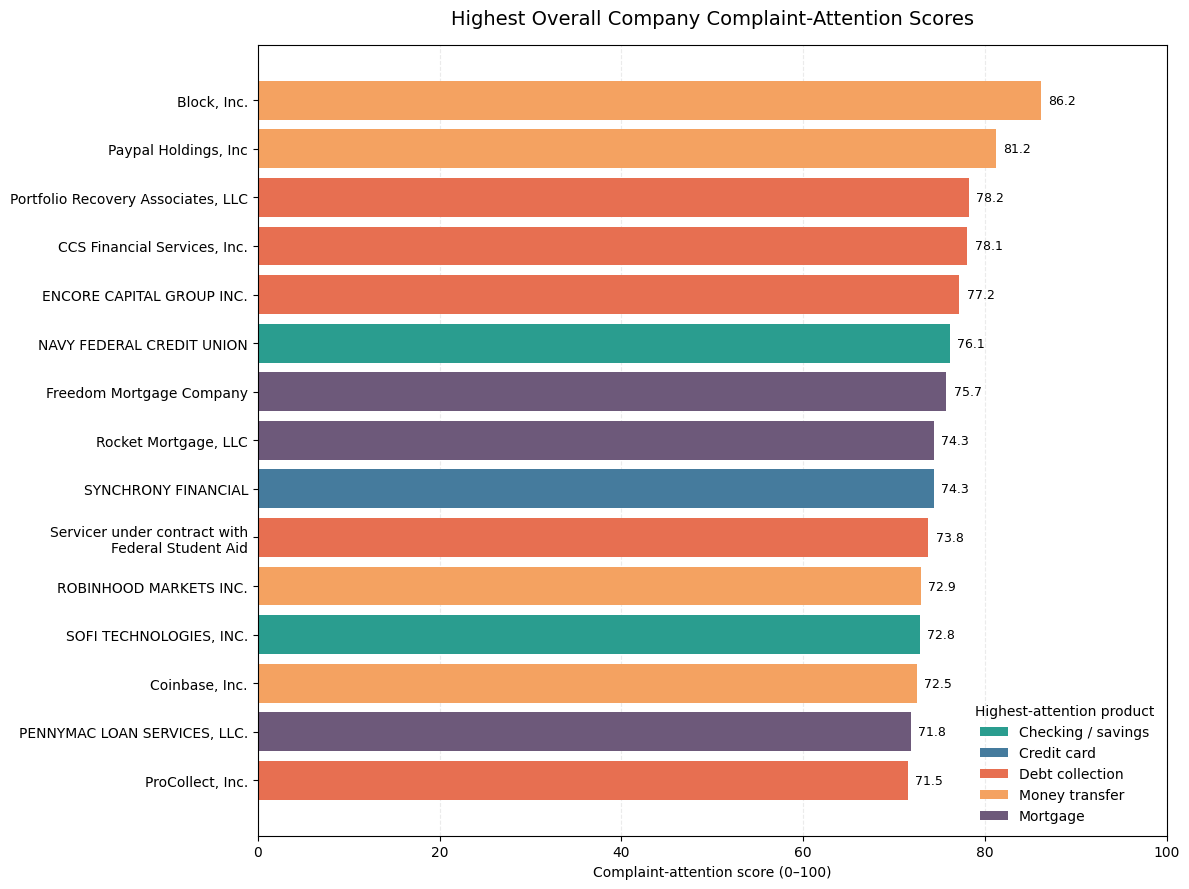

Figure saved to:
/Users/ishika/Documents/AIProject/outputs/notebook8_kpis/figures/overall_company_attention_scores.png


In [17]:
import matplotlib.pyplot as plt
import textwrap
from matplotlib.patches import Patch

NOTEBOOK8_OUTPUT_DIR = (
    PROJECT_DIR /
    "outputs" /
    "notebook8_kpis"
)

NOTEBOOK8_FIGURE_DIR = (
    NOTEBOOK8_OUTPUT_DIR /
    "figures"
)

NOTEBOOK8_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

product_name_map = {
    "Checking or savings account":
        "Checking / savings",
    "Credit card":
        "Credit card",
    "Debt collection":
        "Debt collection",
    "Money transfer, virtual currency, or money service":
        "Money transfer",
    "Mortgage":
        "Mortgage"
}

product_colors = {
    "Checking or savings account": "#2A9D8F",
    "Credit card": "#457B9D",
    "Debt collection": "#E76F51",
    "Money transfer, virtual currency, or money service":
        "#F4A261",
    "Mortgage": "#6D597A"
}

company_plot_data = (
    ranked_companies
    .head(15)
    .sort_values(
        "weighted_company_attention_score",
        ascending=True
    )
    .copy()
)

company_plot_data["company_display"] = (
    company_plot_data["company"]
    .apply(
        lambda value: textwrap.fill(
            value,
            width=35
        )
    )
)

bar_colors = (
    company_plot_data[
        "highest_attention_product"
    ]
    .map(product_colors)
)

fig, ax = plt.subplots(
    figsize=(12, 9)
)

bars = ax.barh(
    company_plot_data["company_display"],
    company_plot_data[
        "weighted_company_attention_score"
    ],
    color=bar_colors
)

ax.set_title(
    "Highest Overall Company Complaint-Attention Scores",
    fontsize=14,
    pad=15
)

ax.set_xlabel(
    "Complaint-attention score (0–100)"
)

ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for bar, score in zip(
    bars,
    company_plot_data[
        "weighted_company_attention_score"
    ]
):
    ax.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.1f}",
        va="center",
        fontsize=9
    )

legend_handles = [
    Patch(
        facecolor=color,
        label=product_name_map[product]
    )
    for product, color in product_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Highest-attention product",
    loc="lower right",
    frameon=False
)

plt.tight_layout()

COMPANY_RANKING_FIGURE = (
    NOTEBOOK8_FIGURE_DIR /
    "overall_company_attention_scores.png"
)

plt.savefig(
    COMPANY_RANKING_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(COMPANY_RANKING_FIGURE)

## 13. Component Profiles of High-Attention Company–Product Combinations

The heatmap displays the within-product percentile of each composite-score component.

A value near 100 means that the company–product combination ranks near the top of its product peers for that indicator. This provides transparency into whether a high score is driven by volume, sentiment, issue severity, untimeliness or monetary-relief patterns.

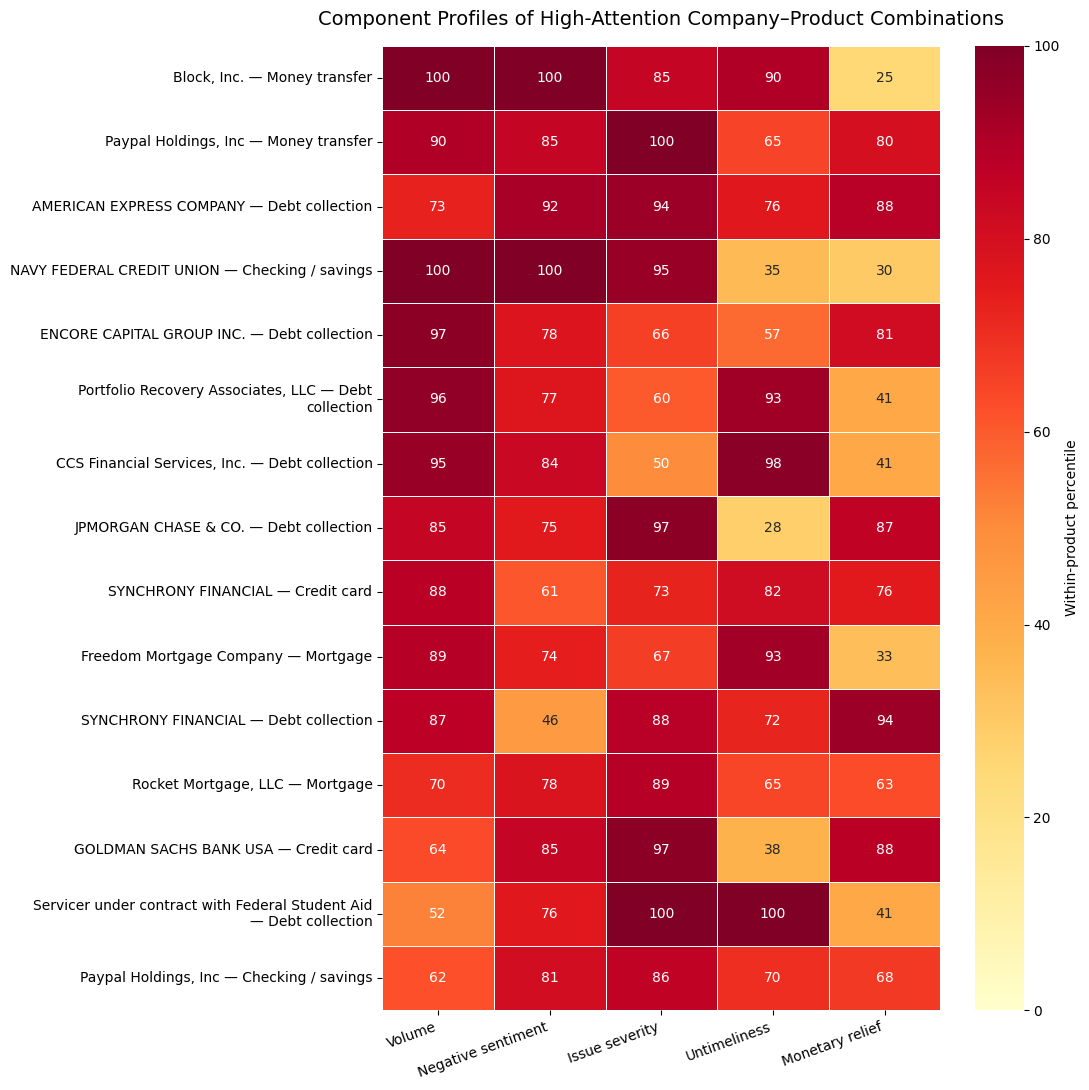

Figure saved to:
/Users/ishika/Documents/AIProject/outputs/notebook8_kpis/figures/company_product_component_heatmap.png


In [19]:
import seaborn as sns

component_plot_data = (
    scored_company_products
    .head(15)
    .copy()
)

component_plot_data["company_product"] = (
    component_plot_data["company"]
    + " — "
    + component_plot_data["product"]
      .map(product_name_map)
)

component_plot_data["company_product"] = (
    component_plot_data["company_product"]
    .apply(
        lambda value: textwrap.fill(
            value,
            width=48
        )
    )
)

component_matrix = (
    component_plot_data
    .set_index("company_product")
    [
        [
            "volume_percentile",
            "negative_sentiment_percentile",
            "issue_severity_percentile",
            "untimely_response_percentile",
            "monetary_relief_percentile"
        ]
    ]
    .rename(
        columns={
            "volume_percentile": "Volume",
            "negative_sentiment_percentile":
                "Negative sentiment",
            "issue_severity_percentile":
                "Issue severity",
            "untimely_response_percentile":
                "Untimeliness",
            "monetary_relief_percentile":
                "Monetary relief"
        }
    )
)

fig, ax = plt.subplots(
    figsize=(11, 11)
)

sns.heatmap(
    component_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={
        "label": "Within-product percentile"
    },
    ax=ax
)

ax.set_title(
    "Component Profiles of High-Attention Company–Product Combinations",
    fontsize=14,
    pad=15
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=20,
    ha="right"
)
plt.tight_layout()

COMPONENT_HEATMAP_FIGURE = (
    NOTEBOOK8_FIGURE_DIR /
    "company_product_component_heatmap.png"
)

plt.savefig(
    COMPONENT_HEATMAP_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(COMPONENT_HEATMAP_FIGURE)

## 14. Export Financial-Intelligence KPI Outputs

The complaint-level intelligence table and all KPI summaries are exported for the SQL analytics layer, dashboard development and portfolio reporting.

The complaint-level export retains all 566,694 complaints. Sentiment and topic fields remain missing for complaints without narratives.

In [20]:
NOTEBOOK8_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Combine issue metrics with their severity scores
issue_kpis_final = issue_kpis.merge(
    eligible_issue_kpis[
        [
            "product",
            "issue",
            "issue_severity_score"
        ]
    ],
    on=["product", "issue"],
    how="left",
    validate="one_to_one"
)

COMPLAINT_MASTER_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "complaint_intelligence_master.csv.gz"
)

PRODUCT_KPI_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "product_kpis.csv"
)

ISSUE_KPI_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "issue_severity_kpis.csv"
)

COMPANY_KPI_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "company_kpis.csv"
)

COMPANY_PRODUCT_KPI_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "company_product_kpis.csv"
)

SCORED_COMPANY_PRODUCT_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "scored_company_product_attention.csv"
)

COMPANY_RANKING_PATH = (
    NOTEBOOK8_OUTPUT_DIR /
    "overall_company_attention_ranking.csv"
)

kpi_data.to_csv(
    COMPLAINT_MASTER_PATH,
    index=False,
    compression="gzip"
)

product_kpis.to_csv(
    PRODUCT_KPI_PATH,
    index=False
)

issue_kpis_final.to_csv(
    ISSUE_KPI_PATH,
    index=False
)

company_kpis.to_csv(
    COMPANY_KPI_PATH,
    index=False
)

company_product_kpis.to_csv(
    COMPANY_PRODUCT_KPI_PATH,
    index=False
)

scored_company_products.to_csv(
    SCORED_COMPANY_PRODUCT_PATH,
    index=False
)

ranked_companies.to_csv(
    COMPANY_RANKING_PATH,
    index=False
)

exported_files = [
    COMPLAINT_MASTER_PATH,
    PRODUCT_KPI_PATH,
    ISSUE_KPI_PATH,
    COMPANY_KPI_PATH,
    COMPANY_PRODUCT_KPI_PATH,
    SCORED_COMPANY_PRODUCT_PATH,
    COMPANY_RANKING_PATH,
    COMPANY_RANKING_FIGURE,
    COMPONENT_HEATMAP_FIGURE
]

export_summary = pd.DataFrame({
    "file": [
        path.name
        for path in exported_files
    ],
    "exists": [
        path.exists()
        for path in exported_files
    ],
    "size_mb": [
        round(
            path.stat().st_size / (1024 ** 2),
            2
        )
        if path.exists()
        else np.nan
        for path in exported_files
    ]
})

display(export_summary)

print(
    "Notebook 8 output directory:",
    NOTEBOOK8_OUTPUT_DIR
)

,file,exists,size_mb
0,complaint_intelligence_master.csv.gz,True,18.25
1,product_kpis.csv,True,0.00
2,issue_severity_kpis.csv,True,0.01
3,company_kpis.csv,True,0.33
4,company_product_kpis.csv,True,0.60
5,scored_company_product_attention.csv,True,0.05
6,overall_company_attention_ranking.csv,True,0.02
7,overall_company_attention_scores.png,True,0.28
8,company_product_component_heatmap.png,True,0.50


Notebook 8 output directory: /Users/ishika/Documents/AIProject/outputs/notebook8_kpis


## 15. Conclusion

This notebook transformed 566,694 CFPB complaints into a structured financial-intelligence KPI framework by combining operational complaint data with sentiment and topic-modelling outputs.

### Data Integration

- Retained all 566,694 complaints for operational analysis.
- Added sentiment and topic intelligence to 272,466 narrative complaints.
- Preserved 294,228 non-narrative complaints for volume, response and relief analysis.
- Achieved 99.81% complaint coverage for the issue-severity framework.

### KPI Framework

Product, company, issue and company–product indicators were calculated using:

- real complaint volume;
- narrative coverage;
- overall and non-template negative sentiment;
- issue-severity exposure;
- untimely-response rates;
- monetary and non-monetary relief outcomes;
- template-heavy narrative prevalence.

Company–product combinations were used as the primary comparative unit because overall company metrics can be distorted by product mix.

### Issue-Severity Indicator

Product–issue severity combined:

- 50% mean negative-sentiment probability;
- 30% monetary-relief rate;
- 20% untimely-response rate.

Components were converted into within-product percentiles before being combined.

### Complaint-Attention Score

The final company–product attention score combined:

- 30% complaint volume;
- 25% non-template negative sentiment;
- 20% issue-severity exposure;
- 15% untimely-response rate;
- 10% monetary-relief rate.

Minimum complaint and narrative thresholds were applied before comparison. All score components were normalised within products so that companies were compared with relevant peers.

### Main Findings

- Money-transfer complaints showed the highest model-predicted negative sentiment, although template-heavy Cash App and Zelle narratives contributed substantially to this result.
- Debt-collection narratives also contained extensive template-heavy and unclustered content.
- Navy Federal retained a strong negative-sentiment signal after template-heavy narratives were excluded.
- Block and PayPal produced the highest overall complaint-attention scores after combining volume, sentiment, issue severity and response outcomes.
- Some smaller companies ranked highly because of concentrated untimeliness or issue severity rather than complaint volume alone.
- Component-level inspection demonstrated that similar composite scores can arise from different operational patterns.

### Interpretation Limitations

The complaint-attention score is a transparent prioritisation tool, not a validated financial-risk, legal-liability or regulatory-compliance score.

Complaint volume is not adjusted for company customer base, transaction volume or market share. Therefore, large companies may naturally generate more complaints.

CFPB complaints represent reported consumer experiences and may contain reporting, selection and duplication biases.

FinBERT sentiment predictions and BERTopic themes are exploratory because no human-labelled complaint reference dataset was used.

Monetary relief may indicate remediation but does not prove company fault. Untimely-response values and company names should also be interpreted within the original CFPB data context.

The component weights, thresholds and attention tiers are documented analytical choices and can be modified for sensitivity analysis.

### Final Deliverables

The notebook exported:

- a 566,694-row complaint-intelligence master table;
- product KPI summaries;
- issue-severity indicators;
- company KPI summaries;
- company–product KPI summaries;
- scored company–product attention indicators;
- overall company rankings;
- presentation-ready KPI visualisations.

These outputs are ready for the SQL analytics layer and subsequent dashboard or application development.